# Describing Data

### What do you find in this notebook?

In this exercise, first, you will familiarize yourself with the Python libraries 'statsmodels' and 'SciPy' that let you do statistical analysis: calculate descriptive statistics, sample datapoints, study relationships between variables, and perform hypothesis testing. Then, second, you will work on a set of exercises that will let you practice your skills.

Here we show a couple of examples of how to do common analyses, but there are many more useful probability distributions and statistical tests. In the linked documentation, you will find complete information, and a lot more details compared to what is outlined in this notebook:
- [statsmodels](https://www.statsmodels.org/stable/examples/index.html), [more complete documentation](https://www.statsmodels.org/stable/stats.html)
- [SciPy](https://docs.scipy.org/doc/scipy/reference/stats.html)

# Tutorial: How to use the libraries

- You will be working with the full US 2015 census dataset (acs2015_county_data.csv, available at https://www.kaggle.com/muonneutrino/us-census-demographic-data#acs2015_county_data.csv). Here we load it. Take some time to familiarize yourself with the contents. One row represents one county.

In [1]:
import pandas as pd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import math

#load the statistical libraries
from statsmodels.stats import diagnostic
from scipy import stats

In [2]:
data_folder = './data/'
df = pd.read_csv(data_folder + 'acs2015_county_data.csv')

In [3]:
df.columns

Index(['CensusId', 'State', 'County', 'TotalPop', 'Men', 'Women', 'Hispanic',
       'White', 'Black', 'Native', 'Asian', 'Pacific', 'Citizen', 'Income',
       'IncomeErr', 'IncomePerCap', 'IncomePerCapErr', 'Poverty',
       'ChildPoverty', 'Professional', 'Service', 'Office', 'Construction',
       'Production', 'Drive', 'Carpool', 'Transit', 'Walk', 'OtherTransp',
       'WorkAtHome', 'MeanCommute', 'Employed', 'PrivateWork', 'PublicWork',
       'SelfEmployed', 'FamilyWork', 'Unemployment'],
      dtype='str')

In [4]:
df.sample(10)

,CensusId,State,County,TotalPop,Men,Women,Hispanic,White,Black,Native,...,Walk,OtherTransp,WorkAtHome,MeanCommute,Employed,PrivateWork,PublicWork,SelfEmployed,FamilyWork,Unemployment
2947,51790,Virginia,Staunton city,24193,10861,13332,2.6,81.6,11.9,0.2,...,5.1,1.9,3.1,19.0,11297,71.7,22.2,5.9,0.2,5.6
272,8055,Colorado,Huerfano,6502,3290,3212,34.6,64.2,0.3,0.1,...,11.4,1.2,5.6,22.0,2211,63.2,24.2,12.2,0.5,15.0
261,8033,Colorado,Dolores,1862,1017,845,5.9,90.7,0.0,1.2,...,25.1,0.3,5.4,17.6,801,69.5,21.7,8.5,0.2,4.6
554,16007,Idaho,Bear Lake,5939,2981,2958,4.1,93.8,0.5,0.1,...,3.2,1.3,5.2,20.0,2598,71.5,17.9,10.3,0.2,3.3
775,18157,Indiana,Tippecanoe,180952,92366,88586,7.9,78.4,4.4,0.1,...,6.3,2.6,3.3,17.6,86629,79.4,16.8,3.7,0.1,6.5
1429,28057,Mississippi,Itawamba,23451,11650,11801,1.5,91.0,6.5,0.0,...,0.3,0.5,2.2,24.5,9428,77.9,16.1,5.8,0.2,9.3
1908,37037,North Carolina,Chatham,67431,33001,34430,12.6,71.4,12.0,0.3,...,1.1,2.6,7.8,28.3,29621,73.0,17.8,9.1,0.2,9.0
2134,40007,Oklahoma,Beaver,5530,2733,2797,21.7,76.0,0.6,0.5,...,2.7,0.8,3.9,19.8,2555,73.3,17.2,9.3,0.2,3.0
1093,21201,Kentucky,Robertson,2208,1100,1108,0.0,99.1,0.0,0.2,...,1.1,0.5,5.5,30.3,806,78.4,18.4,3.2,0.0,6.7
1068,21151,Kentucky,Madison,85838,41648,44190,2.3,90.1,4.4,0.4,...,5.9,2.7,2.6,22.1,39435,76.9,18.8,4.2,0.2,8.6


- We will focus first on income per capita across counties.

Text(0, 0.5, 'Number of counties')

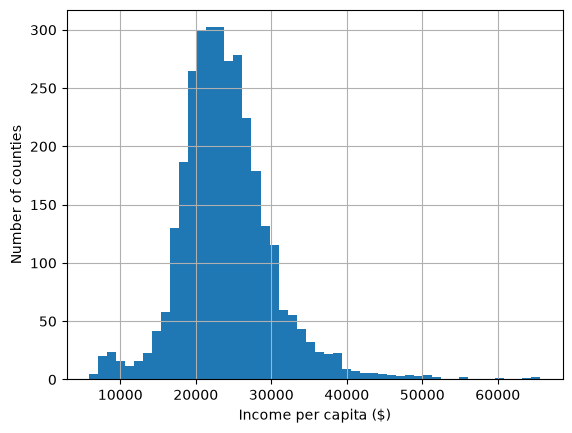

In [5]:
df['IncomePerCap'].hist(bins = 50)
plt.xlabel('Income per capita ($)')
plt.ylabel('Number of counties')


### 1. Calculating descriptive statisctics

- Let's calculate basic descriptive statistics of the income per capita.

In [6]:
df['IncomePerCap'].describe()

count     3220.000000
mean     23981.771739
std       6204.339960
min       5878.000000
25%      20238.500000
50%      23460.000000
75%      27053.250000
max      65600.000000
Name: IncomePerCap, dtype: float64

- What distribution does the data come from? Here is how we can test the goodness of the fit.

It returns a tuple of two numbers: (ksstat, pvalue).

kstest_normal in statsmodels is the Lilliefors test, a version of the Kolmogorov–Smirnov (KS) test. It estimates the mean and standard deviation from your data, then compares your data to a normal distribution with those same parameters.

pvalue

The null hypothesis H₀ is "the data comes from a normal distribution".
The p-value is the probability of seeing a gap at least this big if H₀ were true.
Small p-value (< 0.05): reject H₀, so the data is not normal.
Large p-value (≥ 0.05): you can't reject H₀. That means "no evidence against normality", not proof that the data is normal.

In [7]:
# does the data come from a normal distrbution?
diagnostic.kstest_normal(df['IncomePerCap'].values, dist = 'norm')

(np.float64(0.0637621121184162), np.float64(0.0009999999999998899))

- p_value < 0.05 -> we can reject the null hypothesis that the data comes from a normal distribution!

In [8]:
#how about exponential?
diagnostic.kstest_normal(df['IncomePerCap'].values, dist = 'exp')

(np.float64(0.433243770582646), np.float64(0.0009999999999998899))

- p < 0.05 -> not exponential either!

**important**


The p-value is clipped. With the default pvalmethod='table', statsmodels reads the p-value from a lookup table and limits it to the range [0.001, 0.2]. A result of exactly 0.001 therefore means "0.001 or smaller", and 0.2 means "0.2 or larger".
Large samples reject almost always. With about 3,200 counties, the test spots even tiny deviations from normality. A p-value of 0.001 tells you the data isn't exactly normal, but nothing about how far off it is. Always look at the histogram (or a Q-Q plot) too.
For IncomePerCap you should expect a rejection. The histogram has a long tail to the right (a few very rich counties), and a normal distribution is symmetric.

### 2. How to sample the data

- Often we need to find random samples from the dataset. We can do so conveniently with pandas wrappers.

The replace argument decides whether the same county can be picked more than once.

replace=False (without replacement): you draw a ball and keep it out of the bag. It can't be drawn again, so you get 10 different counties. This is ordinary "pick 10 at random", like dealing cards from a deck.

replace=True (with replacement): you draw a ball, note it, and put it back before the next draw. The same county can come up two or more times, so you might get only 8 or 9 unique counties among your 10 rows.

In [9]:
#make 10 samples with replacement
sample1_counties = df.sample(n = 10, replace = True)

#make 10 samples without replacement
sample1_counties = df.sample(n = 10, replace = False)

#sometimes we want to sample in an ublanaced way, so that we upsample datapoints of certain characteristic,
#and downsample the others. this can be acieved with weights parameter
#here we sample by upsampling counties with large population
sample2_counties = df.sample(n = 10, replace = False, weights = df['TotalPop'])

In [10]:
#on avergage, the samples in the sample produce with reveighting now have higher population, as we wanted!
print(sample1_counties['TotalPop'].mean())
print(sample2_counties['TotalPop'].mean())

42883.4
1282962.5


sample1_counties was drawn without weights, so every county had the same chance. Its mean population should be close to the mean of all counties.

sample2_counties was drawn with weights=df['TotalPop'], so big counties were more likely to be picked. Its mean population should be much higher.

### 3. Examining relationship between two variables

- Is income per capita of a county correlated with the unemployment?

In [11]:
stats.pearsonr(df['IncomePerCap'],df['Employed'])

PearsonRResult(statistic=np.float64(0.2646136320394488), pvalue=np.float64(9.942215354238626e-53))

- There is a small (0.26), but significant (p < 0.05) positive correlation.

In [12]:
stats.spearmanr(df['IncomePerCap'],df['Employed'])

SignificanceResult(statistic=np.float64(0.30770631560595474), pvalue=np.float64(1.4152964311737174e-71))

- Spearman rank coorrelation is also significant.

statistic: how strongly the two variables move together
It ranges from −1 to +1. A value of +1 means the two variables always rise together, 0 means no relationship, and −1 means one always falls as the other rises.
Pearson (r = 0.26) measures a linear relationship: how well a straight line fits the scatter plot.
Spearman (ρ = 0.31) first replaces each value with its rank (1st, 2nd, 3rd, …), then computes Pearson on those ranks. It measures a monotonic relationship ("when one goes up, does the other tend to go up?"), and the line doesn't have to be straight. It's also much less affected by outliers and skewed data.
Your result: both are positive but weak (rough rule of thumb: below 0.3 is weak, 0.3–0.7 moderate, above 0.7 strong). Counties with higher income per capita tend to have somewhat more employed people, with a lot of scatter.

Spearman being a bit higher than Pearson is common with skewed data like yours. A few extreme counties distort Pearson, while the ranks are more robust to them.

2. pvalue: is the correlation different from zero?
The null hypothesis H₀ is "the true correlation is 0".
The p-value is the probability of getting a correlation at least this strong if H₀ were true.
Your p-values are 9.9e-53 and 1.4e-71, which are essentially 0. You reject H₀: the correlation is statistically significant.


### 4. Hypothesis testing

- Is income per capita higher in New York counties compared to California counties?

In [13]:
df.loc[df['State'] == 'New York']['IncomePerCap'].mean()

np.float64(28189.75806451613)

In [14]:
df.loc[df['State'] == 'California']['IncomePerCap'].mean()

np.float64(27902.603448275862)

- We see that there is a ~300$ gap. Quite a lot!
- But is it significantly higher? Let's use a t-test. This is a two-sided test for the null hypothesis that the two independent samples have identical average (expected) values. 

In [15]:
stats.ttest_ind(df.loc[df['State'] == 'New York']['IncomePerCap'], df.loc[df['State'] == 'California']['IncomePerCap'])

TtestResult(statistic=np.float64(0.19788117232375713), pvalue=np.float64(0.8434785239169611), df=np.float64(118.0))

- p is not smaller than 0.05 -> we cannot reject the null hypothesis that the income is the same -> there is no significant difference

### 5. How to measure uncertainty
- Now we see the importance of mesuring uncertainty and indicating it on data visualizations.
- Visual inspection of 95% confidence intervals lets us see that the difference is not significant (the errorbars are overlapping).

(25000.0, 32000.0)

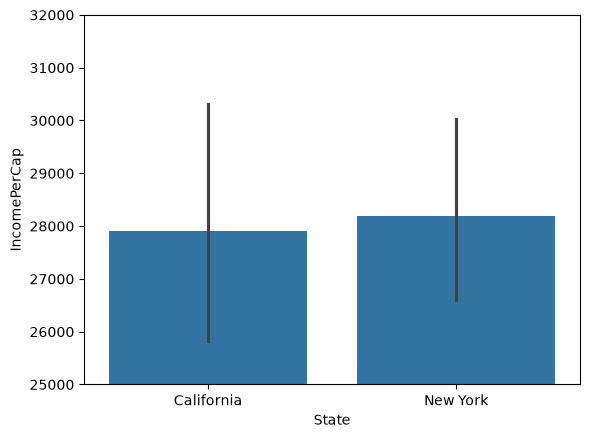

In [16]:
ax = sns.barplot(x="State", y="IncomePerCap", data=df.loc[df['State'].isin(['New York','California'])])
plt.ylim([25000,32000])

# Exercise 1: Boosting the economy by incentivizing self-employment

Assume the biggest priority of the local government in 2018 is to increase per-capita income. To do so, the officials plan to adopt a strategy for incentivizing self-employment through a series of campaigns, educational programs, and dedicated funds.

Since it is unethical and impossible in this setting to run a controlled experiment involving citizens (e.g., fire employees and force them to self-employ), the officials have asked you, the data scientist, to establish the effect of self-employment on the economy, relying on observational data.

**A)** Using suitable methods, determine and quantify the dependency between the percentage of self-employed citizens and per capita income across all 3,212 US counties. Do citizens in counties that have a higher percentage of self-employed people earn more per capita?

Text(0.5, 1.0, 'Self emplyment vs IncomePerCap')

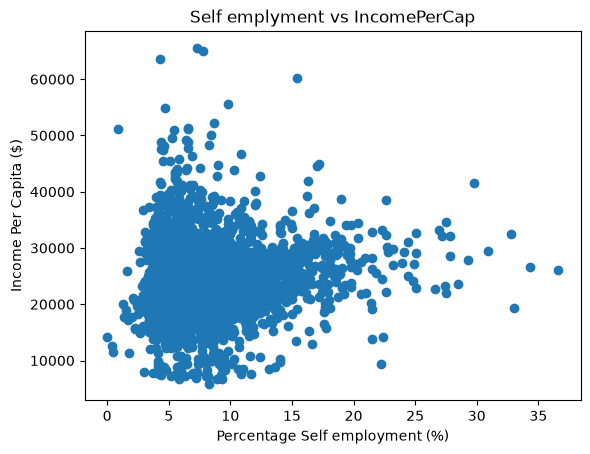

In [17]:
### your code and or answer here ###
plt.scatter(df['SelfEmployed'],df['IncomePerCap'])

plt.xlabel('Percentage Self employment (%)')
plt.ylabel('Income Per Capita ($)')
plt.title('Self emplyment vs IncomePerCap')




Text(0.5, 1.0, 'Self emplyment vs IncomePerCap')

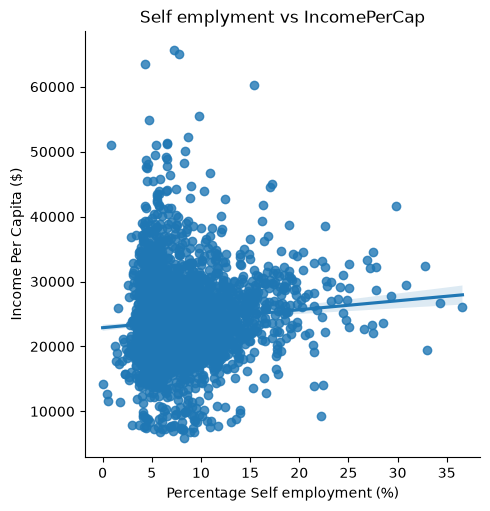

In [18]:
import seaborn as sns

per_capita_self_empl = df[['State','IncomePerCap','SelfEmployed']]

sns.lmplot(x='SelfEmployed', y='IncomePerCap', data=per_capita_self_empl)

plt.xlabel('Percentage Self employment (%)')
plt.ylabel('Income Per Capita ($)')
plt.title('Self emplyment vs IncomePerCap')

In [19]:
print(stats.pearsonr(per_capita_self_empl['SelfEmployed'], per_capita_self_empl['IncomePerCap']))

PearsonRResult(statistic=np.float64(0.08727386609551788), pvalue=np.float64(7.052861196524552e-07))


In [20]:
print(stats.spearmanr(per_capita_self_empl['SelfEmployed'], per_capita_self_empl['IncomePerCap']))

SignificanceResult(statistic=np.float64(0.056413673053189874), pvalue=np.float64(0.0013623847564714563))


**interpretation:**
1. Put a number on how weak it is. Square r to get r² = 0.087² ≈ 0.008. Self-employment rate explains less than 1% of the variation in income per capita between counties. That makes "very weak" concrete.

2. Say why the p-value is so small. With about 3,200 counties, even a tiny correlation is statistically significant. So the correct reading is: "there is almost certainly some positive linear relationship, but it is practically negligible." This is the same "significant does not mean strong" point as before.

3. Check Spearman too. Both variables are skewed, and Pearson is sensitive to outliers (you can probably see a few in the scatter plot). If stats.spearmanr(...) gives a similarly small value, your conclusion is robust. If it differs a lot, that's worth discussing.

4. Answer the question that was actually asked. "Do citizens in counties with a higher percentage of self-employed people earn more per capita?" → Slightly, on average, but the relationship is so weak that self-employment rate is a poor predictor of income.

5. Add the caveat the exercise is setting up. This is observational data, so a correlation is not an effect. Even a stronger correlation wouldn't show that incentivizing self-employment would raise income. Confounders such as rural vs urban, industry mix or age structure could drive both. The government is asking a causal question, and that point will matter again in parts B–D.


**B)** The pilot program will involve all counties within a limited set of three US states. Set A includes Wisconsin, Tennessee, and  Minnesota. Quantify the dependency of per-capita income on self-employment rates across all the counties in set A.

In [21]:
### your code and or answer here ###

set_A = df.loc[df['State'].isin(['Wisconsin','Tennessee','Minnesota'])]
set_A.head(5)


,CensusId,State,County,TotalPop,Men,Women,Hispanic,White,Black,Native,...,Walk,OtherTransp,WorkAtHome,MeanCommute,Employed,PrivateWork,PublicWork,SelfEmployed,FamilyWork,Unemployment
1314,27001,Minnesota,Aitkin,15839,8064,7775,1.1,94.4,0.3,1.8,...,4.3,1.5,5.2,25.1,6428,75.4,15.2,9.2,0.2,7.3
1315,27003,Minnesota,Anoka,338764,169586,169178,3.9,83.8,4.9,0.6,...,1.1,0.9,4.0,28.1,181190,84.7,11.0,4.2,0.1,6.2
1316,27005,Minnesota,Becker,33138,16601,16537,1.8,86.8,0.5,7.0,...,2.9,1.5,6.6,22.8,15929,74.3,16.4,9.0,0.3,3.5
1317,27007,Minnesota,Beltrami,45434,22740,22694,1.9,73.4,0.8,20.0,...,3.2,1.3,6.5,20.2,20579,66.8,26.9,6.2,0.1,10.6
1318,27009,Minnesota,Benton,39221,19500,19721,1.9,92.7,2.3,0.3,...,1.5,1.6,4.9,23.3,20104,82.9,11.2,5.7,0.2,6.7


In [22]:
set_A = set_A[['State','IncomePerCap','SelfEmployed']]
set_A.head(5)

,State,IncomePerCap,SelfEmployed
1314,Minnesota,25591,9.2
1315,Minnesota,31775,4.2
1316,Minnesota,26399,9.0
1317,Minnesota,22524,6.2
1318,Minnesota,25341,5.7


Text(0.5, 1.0, 'Self emplyment vs IncomePerCap')

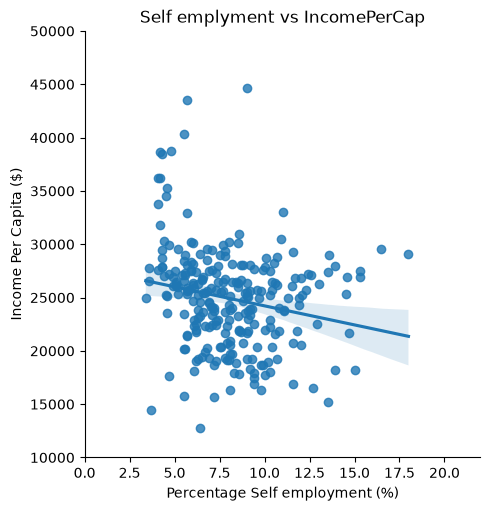

In [23]:
sns.lmplot(x='SelfEmployed', y='IncomePerCap', data=set_A)

plt.xlabel('Percentage Self employment (%)')
plt.ylabel('Income Per Capita ($)')
plt.ylim([10000,50000])
plt.xlim([0,22])
plt.title('Self emplyment vs IncomePerCap')

In [24]:
print(stats.pearsonr(set_A['SelfEmployed'], set_A['IncomePerCap']))

PearsonRResult(statistic=np.float64(-0.202293507365215), pvalue=np.float64(0.001188163932213867))


In [25]:
print(stats.spearmanr(set_A['SelfEmployed'], set_A['IncomePerCap']))

SignificanceResult(statistic=np.float64(-0.2366979000103385), pvalue=np.float64(0.0001401009031365511))


**C)** In which state within set A is the observed effect of self-employment on per-capita income the strongest?

(0.0, 22.0)

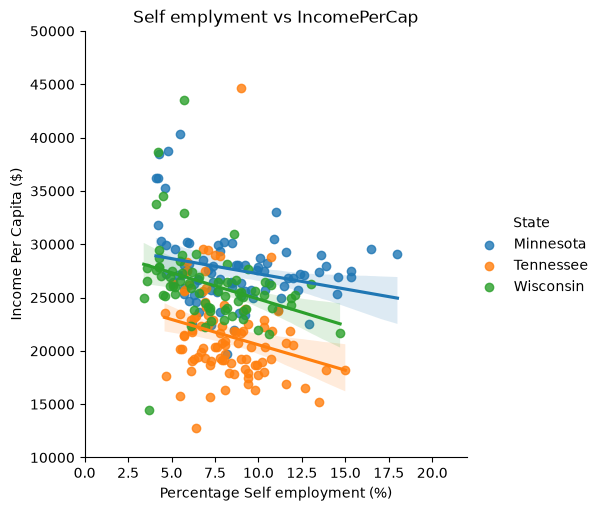

In [26]:
### your code and or answer here ###
sns.lmplot(x='SelfEmployed', y='IncomePerCap', data=set_A, hue='State')

plt.xlabel('Percentage Self employment (%)')
plt.ylabel('Income Per Capita ($)')
plt.title('Self emplyment vs IncomePerCap')
plt.ylim([10000,50000])
plt.xlim([0,22])

In [27]:
set_A_wis = set_A.loc[set_A['State'] == 'Wisconsin']
set_A_ten = set_A.loc[set_A['State'] == 'Tennessee']
set_A_min = set_A.loc[set_A['State'] == 'Minnesota']

print("Wisconsin")
print(stats.pearsonr(set_A_wis['SelfEmployed'], set_A_wis['IncomePerCap']))
print(stats.spearmanr(set_A_wis['SelfEmployed'], set_A_wis['IncomePerCap']))

print("\nTennessee")
print(stats.pearsonr(set_A_ten['SelfEmployed'], set_A_ten['IncomePerCap']))
print(stats.spearmanr(set_A_ten['SelfEmployed'], set_A_ten['IncomePerCap']))

print("\nMinnesota")
print(stats.pearsonr(set_A_min['SelfEmployed'], set_A_min['IncomePerCap']))
print(stats.spearmanr(set_A_min['SelfEmployed'], set_A_min['IncomePerCap']))


Wisconsin
PearsonRResult(statistic=np.float64(-0.32905300016378525), pvalue=np.float64(0.004768134887745218))
SignificanceResult(statistic=np.float64(-0.46351291044049403), pvalue=np.float64(4.124859155565999e-05))

Tennessee
PearsonRResult(statistic=np.float64(-0.23836048684913153), pvalue=np.float64(0.020011631955528044))
SignificanceResult(statistic=np.float64(-0.316991392780988), pvalue=np.float64(0.0017487582457931458))

Minnesota
PearsonRResult(statistic=np.float64(-0.2538551921654062), pvalue=np.float64(0.01766519930091198))
SignificanceResult(statistic=np.float64(-0.21107460598245847), pvalue=np.float64(0.04970805582462063))


**D)** Set B includes New Jersey, Kansas, and Rhode Island. Repeat the analysis from steps B and C above, but now for set B. In which of the two sets A and B (if any) would you recommend incentivizing self-employment? Explain your reasoning. Hint: It is useful to add a notion of confidence to your results and explore the data visually.

Text(0.5, 1.0, 'Self emplyment vs IncomePerCap')

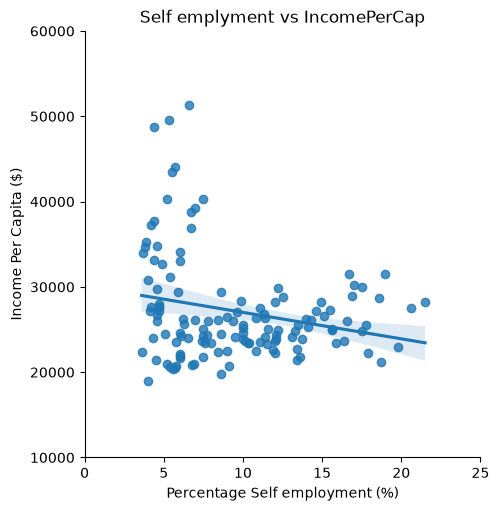

In [28]:
### your code and or answer here ###

set_B = df.loc[df['State'].isin(['New Jersey','Kansas','Rhode Island'])]
set_B = set_B[['State','IncomePerCap','SelfEmployed']]

sns.lmplot(x='SelfEmployed', y='IncomePerCap', data=set_B)

plt.xlabel('Percentage Self employment (%)')
plt.ylabel('Income Per Capita ($)')
plt.ylim([10000,60000])
plt.xlim([0,25])
plt.title('Self emplyment vs IncomePerCap')


In [29]:
print(stats.pearsonr(set_B['SelfEmployed'], set_B['IncomePerCap']))
print(stats.spearmanr(set_B['SelfEmployed'], set_B['IncomePerCap']))

PearsonRResult(statistic=np.float64(-0.23222141346085684), pvalue=np.float64(0.007607493042857458))
SignificanceResult(statistic=np.float64(-0.16010624610827853), pvalue=np.float64(0.0677389077477531))


(0.0, 25.0)

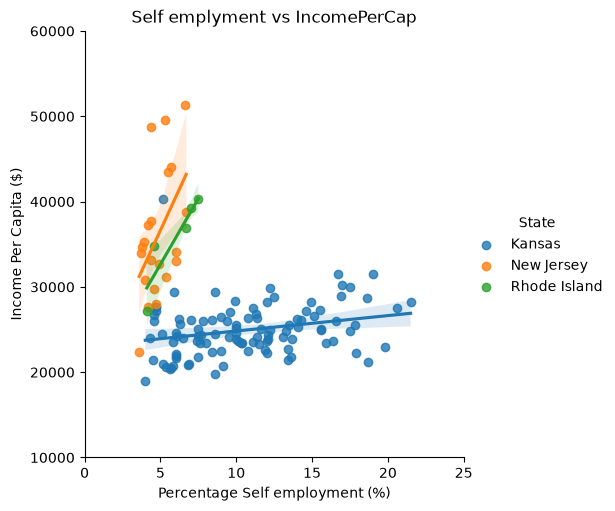

In [30]:
### your code and or answer here ###
sns.lmplot(x='SelfEmployed', y='IncomePerCap', data=set_B, hue='State')

plt.xlabel('Percentage Self employment (%)')
plt.ylabel('Income Per Capita ($)')
plt.title('Self emplyment vs IncomePerCap')
plt.ylim([10000,60000])
plt.xlim([0,25])



In [31]:
set_B_nj = set_B.loc[set_B['State'] == 'New Jersey']
set_B_kan = set_B.loc[set_B['State'] == 'Kansas']
set_B_ri = set_B.loc[set_B['State'] == 'Rhode Island']

print("New Jersey")
print(stats.pearsonr(set_B_nj['SelfEmployed'], set_B_nj['IncomePerCap']))
print(stats.spearmanr(set_B_nj['SelfEmployed'], set_B_nj['IncomePerCap']))

print("\nKansas")
print(stats.pearsonr(set_B_kan['SelfEmployed'], set_B_kan['IncomePerCap']))
print(stats.spearmanr(set_B_kan['SelfEmployed'], set_B_kan['IncomePerCap']))

print("\nMinnesota")
print(stats.pearsonr(set_B_ri['SelfEmployed'], set_B_ri['IncomePerCap']))
print(stats.spearmanr(set_B_ri['SelfEmployed'], set_B_ri['IncomePerCap']))

New Jersey
PearsonRResult(statistic=np.float64(0.4804478471336283), pvalue=np.float64(0.027488944757806125))
SignificanceResult(statistic=np.float64(0.40403460177366013), pvalue=np.float64(0.06929493068926955))

Kansas
PearsonRResult(statistic=np.float64(0.25810299714436913), pvalue=np.float64(0.007853351846832522))
SignificanceResult(statistic=np.float64(0.28392575483491556), pvalue=np.float64(0.0033332825399419908))

Minnesota
PearsonRResult(statistic=np.float64(0.9021788382149805), pvalue=np.float64(0.03618310201575915))
SignificanceResult(statistic=np.float64(0.9999999999999999), pvalue=np.float64(1.4042654220543602e-24))


**Interpretation**:

There is a weak negative dependency overall, moderate to strong positive when disaggregated.
This is a Simpson’s Paradox: the effect is reversed when the data is aggregated.
We would recommend in set B, not in set A (there is significant positive correlation within
all states separately in set B).

# Exercise 2. Data visualization and read the stats comprehension and interpretation questions.

- As part of the quizes, two homeworks and the final exam, you will be at times asked to interpret your result based on the understanding of underlying concepts. The questions below can help you practice and get a sense of how well you understand the concepts covered in the class so far. Can you answer these questions confidently?

### Question 1. The yearly salaries (in thousands of CHF) of 7000 people are summarized in the following box plot. If the 20th percentile of the salaries is 110,000, how many people earn between 110,000 and 114,000?

- a) 2100
- b) 700
- c) 350
- d) 70

<img src="boxplot.png" style="width: 400px;" align="left"/>

In [32]:
### your code and or answer here ###
print("The number of people earning btw 110k-114k is: ", (5/100)*7000)

The number of people earning btw 110k-114k is:  350.0


So the box plot shows from 25th to 75th percentile, so we see graphically that 114k is the vaue of the 25th percentile and from text we have 110k is the 20th percentile.

This let's us conlcude that between 110k-114k there must be 5% of data.

It is answer **C**


### Question 2. What visualizations are suitable for getting insights about the distribution of a single continuous variable?

- a) Barplot and histogram
- b) Boxplot and histogram
- c) Scatterplot and boxplot
- d) Barplot, boxplot, and histogram

In [33]:
### your code and or answer here ###

Not A: Barplot shows one number per category and needs a categorical variable on x-axis and it collapses each group into one number

Answer B: The boxplot gives us an idea about mean, min, max and especiialy about median which is an important indicator of how data is distributed. The histogram shows how the data is distributed and if it has heavy tail etc.

Not C: Scatterplot can give us hints about correlation and therefor needs two variables x, y so anwser C is wrong

Not D: Histogram shows us how a non-continues, descrete variable is distributed

Watch out for the trap: a histogram looks like a barplot because both use bars, but they're different things. In a histogram, the x-axis is the continuous variable cut into bins, and the bar height is a count that is computed for you. In a barplot, the x-axis holds categories, and the bar height is a summary value you chose to show.

So a barplot can't show the distribution of a single continuous variable. That rules out a and d and leaves b.

### Question 3. In a new groundbreaking study, 28 out of 100 patients reported improvements after taking a new medicine. It is known that, when given a placebo, 20% of the patients report feeling better. What is the p-value assuming the null hypothesis that the probability of successful treatment in this groundbreaking study is the same as the probability of reporting feeling better under placebo, according to a one-sided binomial test? Hint: you may use the statsmodels.stats.proportion.binom_test function.

- a) 0.00034
- b) 0.0034
- c) 0.034
- d) 0.34

In [49]:
### your code and or answer here ###
from statsmodels.stats import proportion

p_value = proportion.binom_test(28,100,0.2, alternative='larger')

print(p_value)



0.03415162963907479


The answer is **c** with 0.034 which is smaller than 0.05 so we can reject H_0 and assume that there is an effect in treatment.

prop=0.2: under H₀ the medicine does nothing, so each patient has the placebo rate of a 20% chance of feeling better.
alternative='larger': you only ask whether the true rate is higher than 20%, so only unusually high results count as evidence against H₀.
Reading the p-value in words: if the medicine really had no effect (true rate 20%), the chance of seeing 28 or more improvements out of 100 would be about 3.4%. That's what 'larger' adds up: the probability of 28, 29, 30, and so on up to 100.

The conclusion:

At the usual 5% level, p = 0.034 < 0.05, so you reject H₀. There's evidence that the medicine works better than placebo.
At a stricter 1% level you wouldn't reject. The evidence is real but not overwhelming, and that's worth saying in an answer.
A two-sided test would give about 0.07, which is no longer below 0.05. This shows why the choice of one-sided vs two-sided has to be made before looking at the data, based on the question you're asking.

### Question 4. The 95% confidence interval of the average height of 1000 people using bootstrap resampling with 10000 bootstrap samples is calculated by:

- a) Sampling 1000 height values with replacement and computing the mean. This is repeated 10000 times to create a sorted list of the 10000 means. The CI is defined by the 500th and the 9500th value in sorted order.
- b) Sampling 10000 height values without replacement and computing the mean. This is repeated 1000 times to create a sorted list of the 1000 means. The CI is defined by the 25th and the 975th value in sorted order.
- c) Sampling 1000 height values with replacement and computing the mean. This is repeated 10000 times to create a sorted list of the 10000 means. The CI is defined by the 250th and the 9750th value in sorted order.
- d) Sampling 1000 height values without replacement and computing the mean. This is repeated 10000 times to create a sorted list of the 10000 means. The CI is defined by the 500th and the 9500th value in sorted order.

### Implement your bootstrapping function that you will use in the rest of the course. It should take an array and the number of iterations as inputs, and output 95% confidence intervals of the mean.

Bootstrap uses the fact of replacment so not answer b nor answer d.

Then we know 95% confidence is given by the number of repetitions not the sample size. so we mus get 95% out of 10000. So this means 2.5% from bottom and 2.5% from top so then from 250th to 9750th value in sorted order so it is answer **c**.




In [ ]:
### your code and or answer here ###
nbm_iter = 10000

print(stats.bootstrap(data_arr, np.mean, nbm_iter, confidence_level=0.95))


In [ ]:
#claude version
# 
def bootstrap_CI(data, nbr_draws):
    data = np.asarray(data)
    n = len(data)
    means = np.zeros(nbr_draws)

    for i in range(nbr_draws):
        # one bootstrap sample: n values, with replacement
        sample = np.random.choice(data, size=n, replace=True)
        means[i] = np.mean(sample)

    # 95% CI: cut 2.5% on each side
    return [np.percentile(means, 2.5), np.percentile(means, 97.5)]


In [ ]:
ci = bootstrap_CI(df['IncomePerCap'], 10000)
print(ci)

In [52]:
#solution version
import numpy as np

def bootstrap_confidence_interval(data, iterations=1000):
    """
    Bootstrap the 95% confidence interval for the mean of the data.
    
    Parameters:
    - data: An array of data
    - iterations: The number of bootstrap samples to generate
    
    Returns:
    - A tuple representing the lower and upper bounds of the 95% confidence interval
    """
    means = np.zeros(iterations)
    
    for i in range(iterations):
        bootstrap_sample = np.random.choice(data, size=len(data), replace=True)
        means[i] = np.mean(bootstrap_sample)
        
    lower_bound = np.percentile(means, 2.5)
    upper_bound = np.percentile(means, 97.5)
    
    return (lower_bound, upper_bound)

# Example usage:
data = [2, 4, 6, 8, 10, 12, 14, 16, 18, 20]
print(bootstrap_confidence_interval(data))


(np.float64(7.4), np.float64(14.8))


### Question 5. A study conducted at EPFL revealed a negative Spearman’s correlation between GPA and entry-level job salary. Which of the following statements is true?

- a) There could be a positive Spearman’s correlation between GPA and entry-level job salary in every single department of EPFL.
- b) Spearman correlation between GPA and entry-level job salary in every single department has to be positive.
- c) Across all levels, as opposed to entry-level only, higher GPA scores are associated with higher job salaries.
- d) We can infer that finishing EPFL with a higher GPA causes you to have a lower entry-level job salary.

Answer a: True. Could be true, same idea as for state example seen previously. This is simpsons paradox.

Answer b: False. There is no need for that to be true. It could be that within a deprtement this isn't the case. To generalized.

Answer c: False. There is no need for this to be true and most likely isn't. So need more detailed analysis.

Answer d: False. This isn't intuitive so it needs precise investigation to see underlying effect.

a) ✅ True, Simpson's paradox. You're right. To make it convincing, add a short mechanism: departments differ in both grading and salaries. If departments that grade generously (high GPAs) lead to lower-paid jobs, and strict-grading departments lead to well-paid jobs, the pooled data shows a negative correlation, even though within every department better students earn more. The department is the confounder that flips the sign.

b) ✅ False. Correct. Point to the key word: "has to be". Nothing in the overall result forces the within-department correlations to have any particular sign. They could be positive, negative or zero. Option a only says "could be", and that's why a is true and b is false.

c) ✅ False, but the reason needs fixing. "Most likely isn't" claims more than you know. The real reason: the study only measured entry-level salaries, so it tells us nothing about salaries at other levels. The statement is unsupported, not necessarily false. Don't guess in either direction.

d) ✅ False, but the reason is wrong. "Not intuitive" isn't the argument. A surprising result can still be causal. The real reason is correlation does not imply causation. This is observational data (nobody randomly assigned GPAs), and confounders like department (exactly the mechanism from a) can produce the correlation without GPA having any causal effect. Even a positive correlation wouldn't show causation.

Pattern for these questions: a correlation in observational data can never prove causation (d), and it says nothing beyond the population and variables that were actually measured (c). The overall trend also doesn't fix the trend within subgroups, in either direction (a and b).

In [ ]:
### your code and or answer here ###


### Question 6. The average number of requests per page during a day on a large website is 200, while the median is 15. 

- a) You can assume that the distribution is heavy-tailed.
- b) You are dealing with a left-skewed distribution.
- c) Half of the pages get more than 200 requests.
- d) None of the above.

In [ ]:
### your code and or answer here ###

If mean and median vary that much it means that there are peak number which push the mean up by a lot.

Answer a: False. Probabily one day has a very high value were as others do not have it, so it is possible to have heavy-tailed distribution, but it also could be in the middle if we just average over one week. So we have no indication about if it is a heavy-tailed or not.

Answer b: False. We do not know where the skwed distribution lies on, no information about left, or right

Answer c: No, we know that half of the pages gets more than 15 reuqest not 200.

Answer d: True

Mean and median differ so much because some very large values push the mean up." That's exactly right, and it's the definition of a heavy (long) right tail.

mean > median: the tail is on the right (large values), so the distribution is right-skewed.

A heavy tail means many large values spread out over a long range, like the commune or county populations, and you can't see that from two summary statistics.

The same goes for b: mean > median points toward a right tail if anything, so left-skewed is clearly wrong. And as the solution says, the outlier case shows you can't really conclude "skewed" either.

About your reasoning: your conclusion (d) was right, and so was your instinct that the information isn't enough. Your argument for a was still off, though. The data points are pages within one day, not days in a week. The correct version of your argument is: "one page with a huge value could cause this, so we can't conclude anything about the tail."

Corrected rule: mean ≫ median tells you there are some large values pulling the mean up. It doesn't tell you whether that's a heavy tail or one or two outliers. To tell them apart, look at the distribution with a histogram (log scale if needed) or a CCDF, as in exercise 3.B.